# Implementation of the basic AR model

In [1]:
import glob
import re
import itertools

import matplotlib.pyplot as plt
import scipy.signal
import seaborn as sns
import numpy as np
import pandas as pd

In [2]:
import bidict

In [3]:
import pymc as pm

WARNING (pytensor.tensor.blas): Using NumPy C-API based implementation for BLAS functions.


In [4]:
import arviz as az

In [5]:
import pytensor as pt

In [6]:
from scipy import io

In [7]:
import os

## Data etc

In [8]:
phone_acc_df = pd.read_pickle('data/preprocessed_data/phone_acc_df.pkl')
phone_gyro_df = pd.read_pickle('data/preprocessed_data/phone_gyro_df.pkl')
watch_acc_df = pd.read_pickle('data/preprocessed_data/watch_acc_df.pkl')
watch_gyro_df = pd.read_pickle('data/preprocessed_data/watch_gyro_df.pkl')

In [9]:
activity_codes = bidict.bidict({
    'A': 'walking',
    'B': 'jogging',
    'C': 'stairs',
    'D': 'sitting',
    'E': 'standing',
    'F': 'typing',
    'G': 'teeth',
    'H': 'soup',
    'I': 'chips',
    'J': 'pasta',
    'K': 'drinking',
    'L': 'sandwich',
    'M': 'kicking',
    'O': 'catch',
    'P': 'dribbling',
    'Q': 'writing',
    'R': 'clapping',
    'S': 'folding'
})

In [10]:
activity_groups = {
    "non-hand"   : ['walking', 'jogging', 'stairs', 'standing', "kicking"],
    "hand"       : ["dribbling", "catch", "typing", "writing", "clapping", "teeth", "folding"],
    "hand-eating": ["soup", "chips", "pasta", "sandwich", "drinking"]
}

In [11]:
user_id = 1610

In [12]:
features = pd.read_parquet('data/features.parquet')

In [13]:
features

X0        X1        X2        X3        X4        X5  \
         class                                                               
Eat_avg  1600   0.000000  0.000112  0.604607  0.394944  0.000337  0.000000   
         1601   0.444602  0.555044  0.000354  0.000000  0.000000  0.000000   
         1602   0.109786  0.889198  0.001016  0.000000  0.000000  0.000000   
         1603   0.000088  0.000088  0.000482  0.007544  0.434868  0.555658   
         1604   0.000000  0.000000  0.000056  0.401517  0.597809  0.000506   
...                  ...       ...       ...       ...       ...       ...   
Act_peak 1646   1.000000  0.105000  0.085000  0.110000  0.097500       NaN   
         1647   0.151667  0.437857  0.488824  0.525588  0.526923  0.086250   
         1648   0.586818  0.647609  0.058333       NaN  0.090000  1.000000   
         1649   0.475000  0.567222  0.287727  0.365714  0.762500  1.000000   
         1650   0.541731  0.656875  0.406136  0.080556       NaN       NaN   

                      X6        X7        X8   X9  ...   ZMFCC10   ZMFCC11  \
         class                                     ...                       
Eat_avg  1600   0.000000  0.000000  0.000000  0.0  ...  0.357745  0.353580   
         1601   0.000000  0.000000  0.000000  0.0  ...  0.444904  0.439725   
         1602   0.000000  0.000000  0.000000  0.0  ...  0.438980  0.433869   
         1603   0.001053  0.000132  0.000088  0.0  ...  0.366407  0.362142   
         1604   0.000000  0.000112  0.000000  0.0  ...  0.361698  0.357487   
...                  ...       ...       ...  ...  ...       ...       ...   
Act_peak 1646        NaN       NaN       NaN  NaN  ...  0.357170  0.353012   
         1647        NaN       NaN       NaN  NaN  ...  0.363537  0.359305   
         1648   0.175000       NaN       NaN  NaN  ...  0.381304  0.376864   
         1649        NaN       NaN       NaN  NaN  ...  0.506841  0.500941   
         1650        NaN       NaN       NaN  NaN  ...  0.407978  0.403229   

                 ZMFCC12     XYCOS     XZCOS     YZCOS     XYCOR     XZCOR  \
         class                                                               
Eat_avg  1600   0.349036  0.995514  0.996987  0.998795 -0.274417  0.073085   
         1601   0.434074 -0.843814 -0.994534  0.847225  0.283265  0.206585   
         1602   0.428294  0.974565 -0.987472 -0.993046 -0.164261  0.109770   
         1603   0.357488  0.834449  0.994744  0.843306 -0.142009 -0.572555   
         1604   0.352893  0.995250  0.996765  0.996512 -0.286019 -0.220771   
...                  ...       ...       ...       ...       ...       ...   
Act_peak 1646   0.348475  0.286494  0.779607  0.227093  0.187158  0.015241   
         1647   0.354688 -0.413422 -0.155080  0.714300  0.390524  0.108863   
         1648   0.372022  0.775878  0.555330  0.526420  0.165300  0.359588   
         1649   0.494504  0.531651  0.388995  0.756762  0.025971  0.312698   
         1650   0.404061  0.701162  0.300807  0.210554 -0.106846  0.143372   

                   YZCOR  RESULTANT  
         class                       
Eat_avg  1600  -0.771238   9.331720  
         1601  -0.046499   9.637117  
         1602   0.216951   9.217260  
         1603   0.028999   9.788542  
         1604  -0.396880   9.240737  
...                  ...        ...  
Act_peak 1646   0.365868   9.748891  
         1647   0.024434  10.206332  
         1648   0.335546   9.652113  
         1649   0.206728  10.642357  
         1650   0.362240   9.777502  

[176 rows x 91 columns]

### The target

In [14]:
df_eat = pd.read_parquet("data/df_eat.parquet")

In [15]:
df_act = pd.read_parquet("data/df_act.parquet")

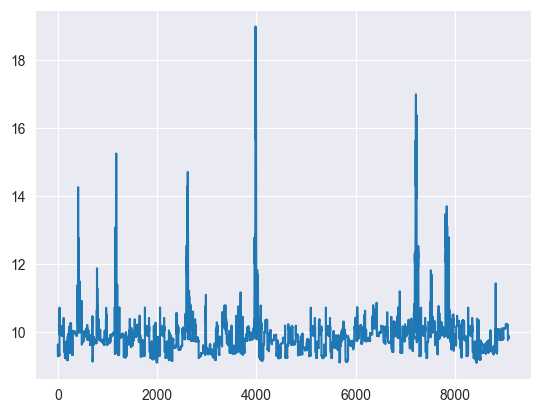

In [16]:
df_act.reset_index()['RESULTANT'].plot();

In [17]:
df_eat.columns

Index(['ACTIVITY', 'X0', 'X1', 'X2', 'X3', 'X4', 'X5', 'X6', 'X7', 'X8', 'X9',
       'Y0', 'Y1', 'Y2', 'Y3', 'Y4', 'Y5', 'Y6', 'Y7', 'Y8', 'Y9', 'Z0', 'Z1',
       'Z2', 'Z3', 'Z4', 'Z5', 'Z6', 'Z7', 'Z8', 'Z9', 'XAVG', 'YAVG', 'ZAVG',
       'XPEAK', 'YPEAK', 'ZPEAK', 'XABSOLDEV', 'YABSOLDEV', 'ZABSOLDEV',
       'XSTANDDEV', 'YSTANDDEV', 'ZSTANDDEV', 'XVAR', 'YVAR', 'ZVAR', 'XMFCC0',
       'XMFCC1', 'XMFCC2', 'XMFCC3', 'XMFCC4', 'XMFCC5', 'XMFCC6', 'XMFCC7',
       'XMFCC8', 'XMFCC9', 'XMFCC10', 'XMFCC11', 'XMFCC12', 'YMFCC0', 'YMFCC1',
       'YMFCC2', 'YMFCC3', 'YMFCC4', 'YMFCC5', 'YMFCC6', 'YMFCC7', 'YMFCC8',
       'YMFCC9', 'YMFCC10', 'YMFCC11', 'YMFCC12', 'ZMFCC0', 'ZMFCC1', 'ZMFCC2',
       'ZMFCC3', 'ZMFCC4', 'ZMFCC5', 'ZMFCC6', 'ZMFCC7', 'ZMFCC8', 'ZMFCC9',
       'ZMFCC10', 'ZMFCC11', 'ZMFCC12', 'XYCOS', 'XZCOS', 'YZCOS', 'XYCOR',
       'XZCOR', 'YZCOR', 'RESULTANT'],
      dtype='object')

In [18]:
df_eat["ACTIVITY"].unique()

array(['H', 'I', 'J', 'K', 'L'], dtype=object)

## Multivariate A-R Model

We can treat the learned characteristics of all the timeseries data observed to-date, as well as the other covariates observed at the same time step, as informative about the structure of the unrealised current state of the predictor. 


In [19]:
test_df = df_eat[["ACTIVITY", "ZSTANDDEV", "ZPEAK", "RESULTANT"]]
test_df["ZSTANDDEV_lag1"] = test_df.groupby(["ACTIVITY"])["ZSTANDDEV"].shift(1)
test_df["ZPEAK_lag1"] = test_df.groupby(["ACTIVITY"])["ZPEAK"].shift(1)
test_df["RESULTANT_lag1"] = test_df.groupby(["ACTIVITY"])["RESULTANT"].shift(1)
test_df = test_df.dropna()

/var/folders/j8/n524q16s54l6y_vxh70gb9lr0000gs/T/ipykernel_13669/3288960215.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  test_df["ZSTANDDEV_lag1"] = test_df.groupby(["ACTIVITY"])["ZSTANDDEV"].shift(1)
/var/folders/j8/n524q16s54l6y_vxh70gb9lr0000gs/T/ipykernel_13669/3288960215.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  test_df["ZPEAK_lag1"] = test_df.groupby(["ACTIVITY"])["ZPEAK"].shift(1)
/var/folders/j8/n524q16s54l6y_vxh70gb9lr0000gs/T/ipykernel_13669/3288960215.py:4: SettingWithCopyWarning

In [20]:
train_df = test_df.iloc[:-100]
test_df = test_df.iloc[-100:]

In [41]:
id_indx_train, unique_ids_train = pd.factorize(train_df["ACTIVITY"])
coords = {"ids": unique_ids_train, "obs": range(len(train_df["RESULTANT"]))}

with pm.Model(coords=coords) as model:
    id_indx = pm.MutableData("id_indx", id_indx_train)
    res_lag1_data = pm.MutableData("res_lag1_data", train_df["RESULTANT_lag1"].values)
    zpeak_data = pm.MutableData("zpeak_data", train_df["ZPEAK"].values)
    zpeak_lag1_data = pm.MutableData("zpeak_lag1_data", train_df["ZPEAK_lag1"].values)
    zstanddev_data = pm.MutableData("zstanddev_data", train_df["ZSTANDDEV"].values)
    zstanddev_lag1_data = pm.MutableData("zstanddev_lag1_data", train_df["ZSTANDDEV_lag1"].values)

    observed = pm.MutableData("observed", train_df["RESULTANT"].values)

    ## Level 1
    global_intercept = pm.Normal("global_intercept", 10, 2)
    global_sigma = pm.HalfStudentT("global_sigma", 1, 3)
    global_res_lag1_beta = pm.Normal("global_res_lag1_beta", 0, 1)
    global_zpeak_beta = pm.Normal("global_zpeak_beta", 0, 1)
    global_zpeak_lag1_beta = pm.Normal("global_zpeak_lag1_beta", 0, 1)
    global_zstanddev_beta = pm.Normal("global_zstanddev_beta", 0, 1)
    global_zstanddev_lag1_beta = pm.Normal("global_zstanddev_lag1_beta", 0, 1)

    subject_intercept_sigma = pm.HalfNormal("subject_intercept_sigma", 2)

    ## Level 2
    subject_intercept = pm.Normal("subject_intercept", 0, subject_intercept_sigma, dims="ids")

    growth_model = pm.Deterministic(
        "growth_model",
        (global_intercept + subject_intercept[id_indx])
        + global_res_lag1_beta * res_lag1_data
        + global_zpeak_beta * zpeak_data
        + global_zpeak_lag1_beta * zpeak_lag1_data
        + global_zstanddev_beta * zstanddev_data
        + global_zstanddev_lag1_beta * zstanddev_lag1_data,
    )

    outcome = pm.Normal(
        "outcome", growth_model, global_sigma, observed=observed, dims="obs"
    )



In [42]:
# TODO: up the nsample values etc, this is just for testing

In [43]:
with model:
    idata_m2 = pm.sample(draws=500, tune=100, chains=2, target_accept=0.95, idata_kwargs={"log_likelihood": True})

Auto-assigning NUTS sampler...
Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (2 chains in 4 jobs)
NUTS: [global_intercept, global_sigma, global_res_lag1_beta, global_zpeak_beta, global_zpeak_lag1_beta, global_zstanddev_beta, global_zstanddev_lag1_beta, subject_intercept_sigma, subject_intercept]


Sampling 2 chains for 100 tune and 500 draw iterations (200 + 1_000 draws total) took 11 seconds.
There were 936 divergences after tuning. Increase `target_accept` or reparameterize.
We recommend running at least 4 chains for robust computation of convergence diagnostics
The rhat statistic is larger than 1.01 for some parameters. This indicates problems during sampling. See https://arxiv.org/abs/1903.08008 for details
The effective sample size per chain is smaller than 100 for some parameters.  A higher number is needed for reliable rhat and ess computation. See https://arxiv.org/abs/1903.08008 for details


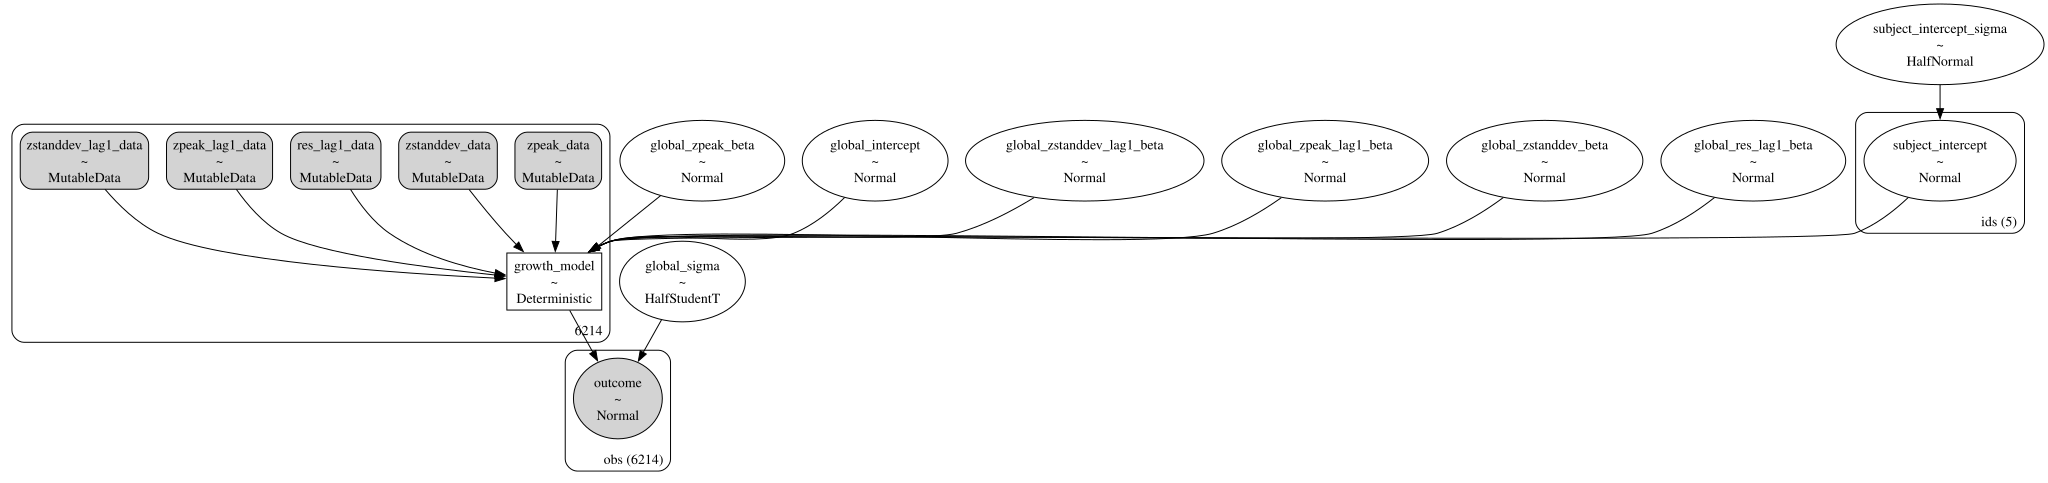

In [32]:
pm.model_to_graphviz(model)

In [ ]:
idata_m2

In [ ]:
az.plot_trace(idata_m2, figsize=(10, 6), kind="rank_vlines");

In [ ]:
az.summary(idata_m2)

In [ ]:
fig, ax = plt.subplots(figsize=(10, 4))
idata_m2.posterior.growth_model.mean(["chain", "draw"]).plot(ax=ax, label="Posterior Mean AR level")
(idata_m2.posterior.growth_model.mean(["chain", "draw"]) + idata_m2.posterior.growth_model.std(["chain", "draw"])).plot(
    ax=ax, ls='--')
(idata_m2.posterior.growth_model.mean(["chain", "draw"]) - idata_m2.posterior.growth_model.std(["chain", "draw"])).plot(
    ax=ax, ls='--')
ax.plot(df_eat.RESULTANT.values, "o", color="black", markersize=2, label="Observed Data")
ax.legend()
ax.set_title("Fitted AR process\nand observed data");


## Predictions

 - Forecast from the  posterior given the observations so far

Old model:

In [22]:
idata_m2

Inference data with groups:
	> posterior
	> posterior_predictive
	> log_likelihood
	> sample_stats
	> prior
	> prior_predictive
	> observed_data
	> constant_data

In [45]:
n = test_df["RESULTANT"].shape[0]

id_indx_test, unique_ids_test = pd.factorize(test_df["ACTIVITY"])

with model:
    model.add_coords({"obs_id_fut": range(n)})

    pm.set_data(
        {
            "id_indx"            : id_indx_test,
            "res_lag1_data"      : test_df["RESULTANT_lag1"].values,
            "zpeak_data"         : test_df["ZPEAK"].values,
            "zpeak_lag1_data"    : test_df["ZPEAK_lag1"].values,
            "zstanddev_data"     : test_df["ZSTANDDEV"].values,
            "zstanddev_lag1_data": test_df["ZSTANDDEV_lag1"].values,
            "observed"           : np.zeros(n),
        }
    )

    outcome_future = pm.Normal("outcome_future", mu=growth_model, sigma=global_sigma, dims="obs_id_fut")

    idata_m2_preds = pm.sample_posterior_predictive(idata_m2, var_names=["outcome_future"], random_seed=100,
                                                    predictions=True)


Sampling: [outcome_future]


In [50]:
idata_m2_preds

Inference data with groups:
	> predictions
	> predictions_constant_data

(5000.0, 6214.0)

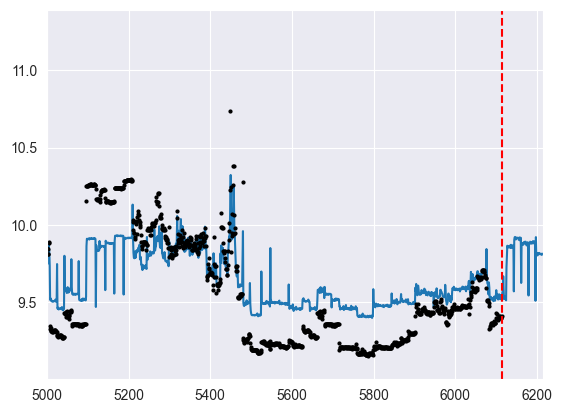

In [58]:
plt.plot(np.concatenate([idata_m2.posterior.growth_model.mean(axis=(0, 1)),
                         idata_m2_preds.predictions["outcome_future"].mean(axis=(0, 1))]))
plt.plot(train_df.RESULTANT.values, "o", color="black", markersize=2, label="Observed Data")
plt.axvline(x=len(train_df), color='r', linestyle='--')
plt.xlim((5000, len(train_df) + len(test_df)))
